<a href="https://colab.research.google.com/github/reallukejin/Econ-Midterm-Project/blob/main/Econ_3916_Midterm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

**Do higher minimum wages lower teen employment? U.S. states, 2015–2024** · Luke Jin

Run top to bottom (*Runtime › Restart and run all*). If you opened this from GitHub in Colab, set `GITHUB_REPO` in the Setup cell first: the notebook clones the repository to reach `data/raw/`.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
import os, re, subprocess
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

GITHUB_REPO = "reallukejin/Econ-Midterm-Project"

# Find data/raw/. If it is not next to the notebook (e.g. a fresh Colab session), clone the repo.
if not os.path.isdir("data/raw"):
    if not os.path.isdir("repo"):
        subprocess.run(["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", "repo"], check=True)
    os.chdir("repo/teen-minwage")
RAW = "data/raw/"
print("Data files found:", sorted(os.listdir(RAW)))

# One plotting style for every figure: thin marks, light grid, no top/right box lines.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8c8c8c"
YEARS = list(range(2015, 2025))

Data files found: ['all-tables-2015.xlsx', 'all-tables-2016.xlsx', 'all-tables-2017.xlsx', 'all-tables-2018.xlsx', 'all-tables-2019.xlsx', 'all-tables-2020.xlsx', 'all-tables-2021.xlsx', 'all-tables-2022.xlsx', 'all-tables-2023.xlsx', 'all-tables-2024.xlsx', 'dol_state_minwage_history.csv', 'fred_cpi_annual.csv', 'fred_median_hh_income.csv']


## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [2]:
SOURCE_URL = {        # the page or file you downloaded from
    "teen and adult employment status by state": "https://www.bls.gov/opub/geographic-profile/ (files: /opub/geographic-profile/{year}/tables/all-tables-{year}.xlsx)",
    "state minimum wage history":              "https://www.dol.gov/agencies/whd/state/minimum-wage/history",
    "median household income by state":        "https://fred.stlouisfed.org/series/MEHOINUSCAA646N (one series per state, MEHOINUS{XX}A646N)",
    "CPI-U, annual average (deflator)":        "https://fred.stlouisfed.org/series/CPIAUCSL",
}
DOWNLOAD_DATE = "2026-11-09"    # YYYY-MM-DD
FILE_NAME = {         # the files as saved in the repository's data/raw/ folder
    "teen and adult employment status by state": "all-tables-2015.xlsx … all-tables-2024.xlsx",
    "state minimum wage history":              "dol_state_minwage_history.csv",
    "median household income by state":        "fred_median_hh_income.csv",
    "CPI-U, annual average (deflator)":        "fred_cpi_annual.csv",
}
pd.set_option("display.max_colwidth", 120)
pd.DataFrame({"source URL": SOURCE_URL, "file in data/raw/": FILE_NAME})

,source URL,file in data/raw/
teen and adult employment status by state,https://www.bls.gov/opub/geographic-profile/ (files: /opub/geographic-profile/{year}/tables/all-tables-{year}.xlsx),all-tables-2015.xlsx … all-tables-2024.xlsx
state minimum wage history,https://www.dol.gov/agencies/whd/state/minimum-wage/history,dol_state_minwage_history.csv
median household income by state,"https://fred.stlouisfed.org/series/MEHOINUSCAA646N (one series per state, MEHOINUS{XX}A646N)",fred_median_hh_income.csv
"CPI-U, annual average (deflator)",https://fred.stlouisfed.org/series/CPIAUCSL,fred_cpi_annual.csv


**Who collected it, for what purpose, what is missing and why?**

*Teen employment.* The Current Population Survey is a monthly household survey run by the Census Bureau for the BLS, designed to produce the *national* unemployment rate. Its sample is allocated so that each state's total unemployment rate is reliable as an annual average, but it was not designed for small subgroups within states. The Geographic Profile therefore publishes a state's 16–19 row only when the estimate meets a minimum-base reliability rule; otherwise the row is left out. Even published teen numbers come from small samples (often a few hundred teenagers per state per year), so the outcome is measured with noticeable sampling error, especially in small states.

*Minimum wage.* DOL records the statutory rate in force on **January 1** of each year. Mid-year increases (e.g. Florida's every September) appear the following year. Where the table shows a range (Minnesota, Nevada, Ohio, Oklahoma) the higher number is the rate for larger employers, which covers most workers, so I use it. States with no law, or a rate below $7.25, are covered by the federal $7.25 for nearly all jobs, so the wage that binds is `max(state rate, federal rate)`. That is the correct value, not an imputation.

*Income.* The Census Bureau's CPS ASEC estimate of state median household income, published in current dollars. I convert it and the minimum wage to **2024 dollars** with the annual CPI-U so that every dollar variable is in the same unit.

The missingness itself is analysed in Section 1 below.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

### 1a. Load and clean each source

In [3]:
STATES = ["Alabama","Alaska","Arizona","Arkansas","California","Colorado","Connecticut","Delaware",
          "District of Columbia","Florida","Georgia","Hawaii","Idaho","Illinois","Indiana","Iowa","Kansas",
          "Kentucky","Louisiana","Maine","Maryland","Massachusetts","Michigan","Minnesota","Mississippi",
          "Missouri","Montana","Nebraska","Nevada","New Hampshire","New Jersey","New Mexico","New York",
          "North Carolina","North Dakota","Ohio","Oklahoma","Oregon","Pennsylvania","Rhode Island",
          "South Carolina","South Dakota","Tennessee","Texas","Utah","Vermont","Virginia","Washington",
          "West Virginia","Wisconsin","Wyoming"]
ABBR = ["AL","AK","AZ","AR","CA","CO","CT","DE","DC","FL","GA","HI","ID","IL","IN","IA","KS","KY","LA","ME",
        "MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ","NM","NY","NC","ND","OH","OK","OR","PA","RI",
        "SC","SD","TN","TX","UT","VT","VA","WA","WV","WI","WY"]

def read_bls_year(year):
    """Pull two rows per state from BLS Table 14: 'Total' (all ages 16+) and 'Men and women, 16 to 19 years'.
    The sheet lists a state name, then that state's rows underneath it, so we remember the
    most recent state name as we walk down the sheet."""
    sheet = pd.read_excel(f"{RAW}all-tables-{year}.xlsx", sheet_name=f"gp{str(year)[2:]}_14", header=None)
    rows, state = [], None
    for r in sheet.itertuples(index=False):
        label = str(r[0]).strip()
        if label in STATES:
            state = label
            continue
        if state is None:
            continue
        if label == "Total":
            group = "all"
        elif label.startswith("Men and women, 16 to 19"):
            group = "teen"
        else:
            continue
        if not any(x["state"] == state and x["group"] == group for x in rows):   # keep the first match only
            # columns: 1 population, 2 labour force, 5 employed as % of population, 6 unemployed (thousands)
            rows.append({"state": state, "year": year, "group": group,
                         "pop": r[1], "lf": r[2], "epop": r[5], "unemp": r[6]})
    return pd.DataFrame(rows)

bls_long = pd.concat([read_bls_year(y) for y in YEARS], ignore_index=True)
for c in ["pop", "lf", "epop", "unemp"]:
    bls_long[c] = pd.to_numeric(bls_long[c], errors="coerce")

# One row per state-year, with the 'all' and 'teen' numbers side by side.
bls = bls_long.pivot_table(index=["state", "year"], columns="group", values=["pop", "lf", "epop", "unemp"])
bls.columns = [f"{v}_{g}" for v, g in bls.columns]
bls = bls.reset_index()
# pivot_table drops state-years with no teen row; put them back as missing so we can study them.
grid = pd.MultiIndex.from_product([STATES, YEARS], names=["state", "year"]).to_frame(index=False)
bls = grid.merge(bls, on=["state", "year"], how="left")
print("BLS:", bls.shape, "| state-years with a published teen row:", bls["epop_teen"].notna().sum())

BLS: (510, 10) | state-years with a published teen row: 386


In [4]:
def parse_wage(text):
    """'5.15(d)' -> 5.15 ; '7.25-9.00(g)' -> 9.00 (higher, large-employer rate) ; '...' (no law) -> NaN"""
    text = re.sub(r"\(.*?\)|\[.*?\]|\$", "", str(text))          # drop footnote letters and $ signs
    numbers = [float(n) for n in re.findall(r"\d+\.\d+", text)]
    return max(numbers) if numbers else np.nan

dol = pd.read_csv(RAW + "dol_state_minwage_history.csv")
dol = dol[dol["column_header"].astype(str).isin([str(y) for y in YEARS])].copy()
dol["year"] = dol["column_header"].astype(int)
dol["mw_state"] = dol["value_as_published"].map(parse_wage)

federal = dol[dol["jurisdiction"].str.startswith("Federal")].set_index("year")["mw_state"].rename("mw_federal")
mw = dol[dol["jurisdiction"].isin(STATES)].rename(columns={"jurisdiction": "state"}).join(federal, on="year")
mw["mw"] = mw[["mw_state", "mw_federal"]].max(axis=1)        # the binding wage
mw["no_state_law"] = mw["mw_state"].isna()
print("DOL:", mw.shape, "| state-years with no state law:", mw["no_state_law"].sum(),
      "| state-years where the federal rate binds:", (mw["mw"] == mw["mw_federal"]).sum())
mw[["state", "year", "value_as_published", "mw_state", "mw"]].query("state in ['Georgia','Minnesota','California'] and year in [2015, 2024]")

DOL: (510, 9) | state-years with no state law: 50 | state-years where the federal rate binds: 206


,state,year,value_as_published,mw_state,mw
1571,California,2015,9.00,9.00,9.00
1601,Georgia,2015,5.15(d),5.15,7.25
1679,Minnesota,2015,7.25-9.00(g),9.00,9.00
1899,California,2024,16.00,16.00,16.00
1924,Georgia,2024,5.15(d),5.15,7.25
1989,Minnesota,2024,10.85(g),10.85,10.85


In [5]:
cpi = pd.read_csv(RAW + "fred_cpi_annual.csv")
cpi["year"] = pd.to_datetime(cpi["observation_date"]).dt.year
cpi = cpi.set_index("year")["CPIAUCSL"]
to_2024_dollars = cpi.loc[2024] / cpi                          # multiply a year-t dollar amount by this

inc = pd.read_csv(RAW + "fred_median_hh_income.csv")
inc["year"] = pd.to_datetime(inc["date"]).dt.year
inc["state"] = inc["state_abbr"].map(dict(zip(ABBR, STATES)))
inc = inc[inc["year"].isin(YEARS)][["state", "year", "median_hh_income_current_dollars"]]
print("FRED income:", inc.shape, "| CPI 2015 and 2024:", cpi.loc[2015], cpi.loc[2024])

FRED income: (510, 3) | CPI 2015 and 2024: 237.002 313.698


### 1b. Merge and build the model variables

* `teen_epop` (outcome): employed 16–19 year olds as a % of all civilian non-institutional 16–19 year olds.
* `log_real_mw` (main X): log of the binding minimum wage in 2024 dollars. A log lets the coefficient be read as "a 10% higher minimum wage goes with a change of β/10 percentage points".
* `adult_unemp`: unemployment rate of people **20 and over**, built as (all unemployed − teen unemployed) / (all labour force − teen labour force). The usual state unemployment rate includes teenagers, so it would partly contain the outcome.
* `teen_share`: 16–19 year olds as a % of the 16+ population.
* `log_real_inc`: log median household income in 2024 dollars.

In [6]:
df = (bls.merge(mw[["state", "year", "mw", "no_state_law"]], on=["state", "year"], how="left")
         .merge(inc, on=["state", "year"], how="left"))
df["real_mw"] = df["mw"] * df["year"].map(to_2024_dollars)
df["real_inc"] = df["median_hh_income_current_dollars"] * df["year"].map(to_2024_dollars)
df["teen_epop"] = df["epop_teen"]
df["log_real_mw"] = np.log(df["real_mw"])
df["log_real_inc"] = np.log(df["real_inc"])
df["adult_unemp"] = 100 * (df["unemp_all"] - df["unemp_teen"]) / (df["lf_all"] - df["lf_teen"])
df["teen_share"] = 100 * df["pop_teen"] / df["pop_all"]
df["teen_missing"] = df["teen_epop"].isna()

MODEL_VARS = ["teen_epop", "log_real_mw", "adult_unemp", "teen_share", "log_real_inc"]
sample = df.dropna(subset=MODEL_VARS).copy()                     # the estimation sample
print(f"Merged panel: {df.shape[0]} state-years. Estimation sample: {len(sample)} state-years, "
      f"{sample['state'].nunique()} states.")
print("States never in the sample:", sorted(set(STATES) - set(sample["state"])))
df.head()

Merged panel: 510 state-years. Estimation sample: 386 state-years, 48 states.
States never in the sample: ['District of Columbia', 'Maine', 'South Dakota']


,state,year,epop_all,epop_teen,lf_all,lf_teen,pop_all,pop_teen,unemp_all,unemp_teen,...,no_state_law,median_hh_income_current_dollars,real_mw,real_inc,teen_epop,log_real_mw,log_real_inc,adult_unemp,teen_share,teen_missing
0,Alabama,2015,53.2,25.3,2155.0,82.0,3803.0,275.0,132.0,13.0,...,True,44510,9.596166,58913.840305,25.3,2.261364,10.983831,5.740473,7.231133,False
1,Alabama,2016,53.4,26.6,2167.0,81.0,3816.0,244.0,131.0,16.0,...,True,47220,9.476096,61718.795692,26.6,2.248772,11.030344,5.512943,6.394130,False
2,Alabama,2017,53.9,24.1,2160.0,74.0,3830.0,260.0,94.0,11.0,...,True,50870,9.278318,65101.795685,24.1,2.227680,11.083707,3.978907,6.788512,False
3,Alabama,2018,55.1,27.9,2208.0,75.0,3847.0,236.0,87.0,9.0,...,True,49940,9.057389,62389.797372,27.9,2.203581,11.041157,3.656821,6.134650,False
4,Alabama,2019,56.9,NaN,2263.0,NaN,3862.0,NaN,67.0,NaN,...,True,56200,8.896084,68959.987170,NaN,2.185611,11.141282,NaN,NaN,True


In [7]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "state-year"          # one row is one what? e.g. "county" or "country-year"
OUTCOME = "teen_epop"        # your dependent variable's column name
MAIN_X = "log_real_mw"       # your main explanatory variable's column name
CONTROLS = ["adult_unemp", "teen_share", "log_real_inc"]   # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 510   Columns: 21   One row is: state-year

Missing values per column:
teen_epop       124
log_real_mw       0
adult_unemp     124
teen_share      124
log_real_inc      0

Skew of teen_epop: 0.53 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

**My answers.**

1. Adult unemployment: probably a little, like if a higher minimum wage also costs low-wage adults their jobs. Median household income: probably a little too, since a higher floor basically raises pay at the low end. Teen population share: no. A state’s minimum wage doesn’t really change how many 16–19 year olds live there within a few years. The first two could partly sit on the path from X to Y, so Section 3 runs the model with and without them and says what each version measures.
2. Yes. Every variable is basically per state per calendar year, 2015–2024, for the same 51 jurisdictions. Both dollar variables are converted to 2024 dollars with the same CPI series, and rates are in percent.
3. There’s no single policy date. Minimum wages change at different times in different states over the decade: 28 of the 48 states in the sample change their binding wage at least once, and 20 stay at the federal $7.25 the whole time. So basically every year has states that changed and states that didn’t.

**Question.** Within U.S. states, 2015–2024, is a higher real minimum wage associated with a lower employment rate (percent of 16–19 year olds employed) among teenagers?

**Why it matters, and to whom.** Teenagers are the group most likely to earn at or near the minimum wage, so any job loss from a higher floor should show up there first. That matters to state legislators voting on increases and to the teenagers and small employers on either side of those jobs. The federal minimum has been $7.25 since 2009, so all variation in this decade comes from state law.

**Hypothesis (written before the model).** Negative: if a higher wage floor makes employers hire fewer low-wage workers, teen employment should fall.

### 1c. Summary statistics (estimation sample)

In [8]:
LABELS = {
    "teen_epop": "Teen employment rate (% of 16–19 pop.)",
    "real_mw": "Minimum wage, binding (2024 $/hour)",
    "adult_unemp": "Unemployment rate, ages 20+ (%)",
    "teen_share": "Teens as % of 16+ population",
    "real_inc": "Median household income (2024 $)",
}
summary = sample[list(LABELS)].describe().T[["count", "mean", "std", "min", "50%", "max"]]
summary.index = summary.index.map(LABELS)
summary.columns = ["N", "Mean", "Std. dev.", "Min", "Median", "Max"]
summary["N"] = summary["N"].astype(int)
summary_fmt = summary.copy()
for c in ["Mean", "Std. dev.", "Min", "Median", "Max"]:
    summary_fmt[c] = [f"{v:,.0f}" if "income" in i else f"{v:,.2f}" for i, v in zip(summary.index, summary[c])]
print(f"Table 1. Summary statistics, {len(sample)} state-years ({sample['state'].nunique()} states), 2015–2024. "
      "Sources: BLS Geographic Profile Table 14; DOL; FRED. Dollar values deflated to 2024 with CPI-U.")
summary_fmt

Table 1. Summary statistics, 386 state-years (48 states), 2015–2024. Sources: BLS Geographic Profile Table 14; DOL; FRED. Dollar values deflated to 2024 with CPI-U.


,N,Mean,Std. dev.,Min,Median,Max
Teen employment rate (% of 16–19 pop.),386,33.69,8.19,18.70,33.10,58.30
"Minimum wage, binding (2024 $/hour)",386,10.62,2.25,7.25,10.32,16.57
"Unemployment rate, ages 20+ (%)",386,4.34,1.52,2.10,3.97,12.64
Teens as % of 16+ population,386,6.57,0.59,5.13,6.54,8.64
Median household income (2024 $),386,"79,621","12,976","52,997","78,740","114,872"


### 1d. Missingness: which state-years are missing the teen numbers, and why?

In [9]:
miss_by_year = df.groupby("year")["teen_missing"].sum()
print("Teen row missing, by year:\n", miss_by_year.to_string())
print(f"\nTotal: {df['teen_missing'].sum()} of {len(df)} state-years ({100*df['teen_missing'].mean():.1f}%)")

# Compare missing and non-missing state-years on things we DO observe for every row.
compare = df.groupby("teen_missing").agg(
    state_years=("state", "size"),
    pop_16plus_thousands=("pop_all", "median"),
    real_min_wage=("real_mw", "mean"),
    overall_employment_rate=("epop_all", "mean"),
    real_median_income=("real_inc", "mean"))
compare.index = ["Teen row published", "Teen row missing"]
compare.round(2)

Teen row missing, by year:
 year
2015     6
2016     7
2017    13
2018    17
2019    21
2020     4
2021    14
2022    16
2023    14
2024    12

Total: 124 of 510 state-years (24.3%)


,state_years,pop_16plus_thousands,real_min_wage,overall_employment_rate,real_median_income
Teen row published,386,4527.0,10.62,59.71,79620.93
Teen row missing,124,1136.5,11.59,62.71,86241.22


In [10]:
# Does missingness depend on more than state size? Logit of 'missing' on observed variables + year dummies.
miss_logit = smf.logit("teen_missing ~ np.log(pop_all) + log_real_mw + epop_all + C(year)",
                       data=df.assign(teen_missing=df["teen_missing"].astype(int))).fit(disp=0)
miss_tab = pd.DataFrame({"coef": miss_logit.params, "std err": miss_logit.bse, "p": miss_logit.pvalues}).loc[
    ["np.log(pop_all)", "log_real_mw", "epop_all"]].round(3)
miss_tab

,coef,std err,p
np.log(pop_all),-1.066,0.140,0.000
log_real_mw,2.027,0.585,0.001
epop_all,0.127,0.032,0.000


**Mechanism: MNAR, mostly through state size. BLS drops a state's teen row when the estimate is too small to meet its reliability rule. That rule is about how big the teen estimates are, which is the outcome's own territory, so the missingness is not at random by design. Small states are missed most (the median missing state-year has about a quarter of the population of a published one), and DC, Maine and South Dakota are never published. If population were the whole story, the label would be MAR (missing at random given an observed variable). But the logit shows that, *holding population fixed*, a state-year is more likely to be missing when its overall employment rate is higher and its minimum wage is higher. A tight labour market means fewer unemployed teenagers to count, which is exactly the condition that pushes the teen estimate under the threshold. So missingness depends on teen labour-market conditions themselves: MNAR.

*What it does to the answer.* The dropped rows are disproportionately high-wage, strong-labour-market state-years, where teen employment is probably *higher* than average. Dropping high-wage, high-teen-employment observations tilts the sample toward finding a negative relationship, so the minimum-wage coefficient is, if anything, biased **away from zero** (too negative). The estimate also only describes the 48 states that are ever published.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

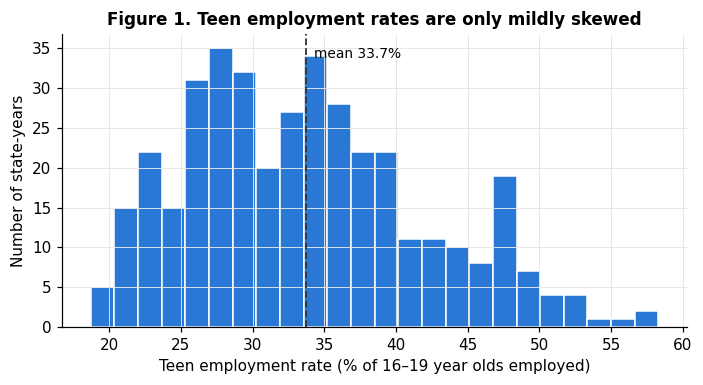

Skew of teen employment rate: 0.53; of real minimum wage: 0.57; of real median income: 0.21


In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(sample["teen_epop"], bins=24, color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(sample["teen_epop"].mean(), color="#333333", linewidth=1.2, linestyle="--")
ax.text(sample["teen_epop"].mean() + 0.6, ax.get_ylim()[1] * 0.92,
        f"mean {sample['teen_epop'].mean():.1f}%", fontsize=9)
ax.set_xlabel("Teen employment rate (% of 16–19 year olds employed)")
ax.set_ylabel("Number of state-years")
ax.set_title("Figure 1. Teen employment rates are only mildly skewed")
plt.tight_layout(); plt.savefig("fig1_outcome_distribution.png", dpi=200); plt.show()
print(f"Skew of teen employment rate: {sample['teen_epop'].skew():.2f}; "
      f"of real minimum wage: {sample['real_mw'].skew():.2f}; of real median income: {sample['real_inc'].skew():.2f}")

**Figure 1.** Across state-years, teen employment rates are spread roughly symmetrically around their mean, with a mild right tail (skew printed above, well under 1). **I keep the outcome in levels**, so coefficients are in percentage points. The two dollar variables go in as logs, because their effects are better thought of in percentage terms and the minimum wage is right-skewed (a cluster at $7.25 and a long upper tail).

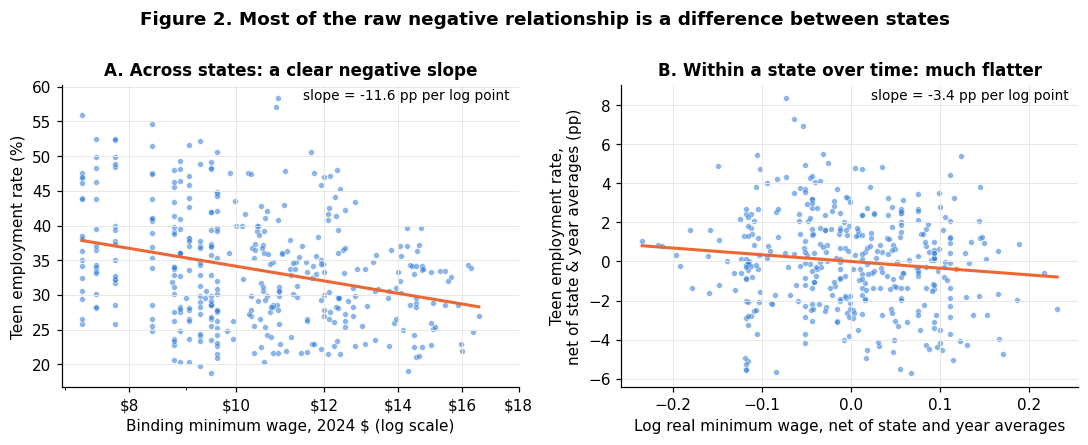

In [12]:
# Remove state and year averages ("demeaning") to see the variation the fixed-effects model uses.
def within(col):
    x = sample[col]
    return x - sample.groupby("state")[col].transform("mean") - sample.groupby("year")[col].transform("mean") + x.mean()

sample["teen_epop_within"] = within("teen_epop")
sample["log_real_mw_within"] = within("log_real_mw")

pooled_slope = np.polyfit(sample["log_real_mw"], sample["teen_epop"], 1)[0]
within_slope = np.polyfit(sample["log_real_mw_within"], sample["teen_epop_within"], 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
ax = axes[0]
ax.scatter(sample["real_mw"], sample["teen_epop"], s=14, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.4)
xs = np.linspace(sample["log_real_mw"].min(), sample["log_real_mw"].max(), 50)
b = np.polyfit(sample["log_real_mw"], sample["teen_epop"], 1)
ax.plot(np.exp(xs), b[1] + b[0] * xs, color=ORANGE, linewidth=2)
ax.set_xscale("log"); ax.set_xticks([8, 10, 12, 14, 16, 18]); ax.set_xticklabels(["$8", "$10", "$12", "$14", "$16", "$18"])
ax.set_xlabel("Binding minimum wage, 2024 $ (log scale)"); ax.set_ylabel("Teen employment rate (%)")
ax.set_title("A. Across states: a clear negative slope")
ax.text(0.98, 0.95, f"slope = {pooled_slope:.1f} pp per log point", transform=ax.transAxes, ha="right", fontsize=9)

ax = axes[1]
ax.scatter(sample["log_real_mw_within"], sample["teen_epop_within"], s=14, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.4)
xs = np.linspace(sample["log_real_mw_within"].min(), sample["log_real_mw_within"].max(), 50)
b = np.polyfit(sample["log_real_mw_within"], sample["teen_epop_within"], 1)
ax.plot(xs, b[1] + b[0] * xs, color=ORANGE, linewidth=2)
ax.set_xlabel("Log real minimum wage, net of state and year averages")
ax.set_ylabel("Teen employment rate,\nnet of state & year averages (pp)")
ax.set_title("B. Within a state over time: much flatter")
ax.text(0.98, 0.95, f"slope = {within_slope:.1f} pp per log point", transform=ax.transAxes, ha="right", fontsize=9)
fig.suptitle("Figure 2. Most of the raw negative relationship is a difference between states", fontweight="bold", y=1.0)
plt.tight_layout(); plt.savefig("fig2_pooled_vs_within.png", dpi=200, bbox_inches="tight"); plt.show()

**Figure 2.** Panel A: states with higher minimum wages have markedly lower teen employment rates. Panel B removes each state's own average and each year's national average, which is the comparison the fixed-effects model makes: a state against itself in other years. The slope shrinks to under a third of its size (slopes printed on each panel). Most of the raw gap is about *which* states have high minimum wages (large, urban, high-cost states, where teens work less for many reasons), not about what happens when a given state raises its wage. Both axes show the full range of the data; the x-axis in A is logarithmic because the model uses the log wage.

/tmp/ipykernel_460/596773913.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: np.average(g["teen_epop"], weights=g["pop_teen"])).unstack(0))


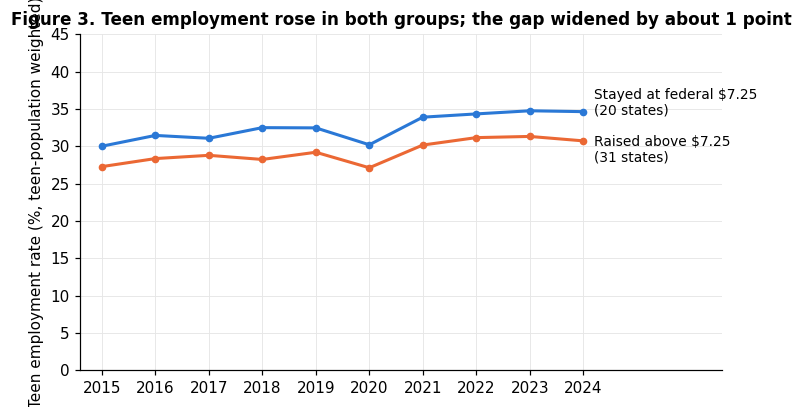

group  Raised above $7.25  Stayed at federal $7.25
year                                              
2015                 27.3                     30.0
2016                 28.3                     31.4
2017                 28.8                     31.1
2018                 28.2                     32.5
2019                 29.2                     32.5
2020                 27.1                     30.2
2021                 30.2                     33.9
2022                 31.1                     34.3
2023                 31.3                     34.7
2024                 30.7                     34.6

Gap (federal-floor minus raised), 2015: 2.7 pp; 2024: 3.9 pp


In [13]:
# Group states by what happened to their minimum wage over the decade.
first_last = df.groupby("state")["mw"].agg(["first", "last"])
federal_floor = first_last.index[(first_last["first"] == 7.25) & (first_last["last"] == 7.25)]
df["group"] = np.where(df["state"].isin(federal_floor), "Stayed at federal $7.25", "Raised above $7.25")
trend = (df.dropna(subset=["teen_epop"]).groupby(["group", "year"])
           .apply(lambda g: np.average(g["teen_epop"], weights=g["pop_teen"])).unstack(0))
n_states = df.groupby("group")["state"].nunique()

fig, ax = plt.subplots(figsize=(7, 3.8))
for name, color in [("Raised above $7.25", ORANGE), ("Stayed at federal $7.25", BLUE)]:
    ax.plot(trend.index, trend[name], color=color, linewidth=2, marker="o", markersize=4)
    offset = 1.2 if name.startswith("Stayed") else -1.2
    ax.text(2024.2, trend[name].iloc[-1] + offset, f"{name}\n({n_states[name]} states)", va="center", fontsize=9)
ax.set_ylim(0, 45); ax.set_xlim(2014.6, 2026.6); ax.set_xticks(YEARS)
ax.set_ylabel("Teen employment rate (%, teen-population weighted)")
ax.set_title("Figure 3. Teen employment rose in both groups; the gap widened by about 1 point")
plt.tight_layout(); plt.savefig("fig3_trends_by_group.png", dpi=200); plt.show()
print(trend.round(1).to_string())
gap = trend["Stayed at federal $7.25"] - trend["Raised above $7.25"]
print(f"\nGap (federal-floor minus raised), 2015: {gap.loc[2015]:.1f} pp; 2024: {gap.loc[2024]:.1f} pp")

**Figure 3.** States that kept the federal $7.25 all decade had higher teen employment than states that raised their wage *before* most increases took effect (2015), and both groups follow the same path: a dip in 2020, then a rise to a decade high. As the raised-wage states pulled further ahead in wages, the gap widened by about one percentage point (2.7 to 3.9 points, printed above). That is a modest change next to the overall rise both groups shared, and of the same order as the fixed-effects estimate in Section 3. The y-axis starts at zero so the gap is drawn to scale. Because small states' teen numbers are sometimes unpublished, the set of states behind each year's average changes slightly from year to year.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

The main model is

$$\text{teen\_epop}_{st} = \beta_1 \log(\text{real MW})_{st} + \beta_2\,\text{adult\_unemp}_{st} + \beta_3\,\text{teen\_share}_{st} + \beta_4 \log(\text{real income})_{st} + \alpha_s + \gamma_t + \varepsilon_{st}$$

with a dummy for every state ($\alpha_s$) and every year ($\gamma_t$). Columns (1)–(2) leave the dummies out to show how much they matter; columns (3) and (4) drop one or both of the two controls that the minimum wage might itself move.
Standard errors are heteroskedasticity-robust (HC1). The Breusch–Pagan test in Section 4 is borderline (it does not reject at 5%), so robust errors are a precaution; they are almost identical to the classical ones.

In [14]:
SPECS = {
    "(1) Pooled, no controls": "teen_epop ~ log_real_mw",
    "(2) Pooled, controls": "teen_epop ~ log_real_mw + adult_unemp + teen_share + log_real_inc",
    "(3) FE, teen share only": "teen_epop ~ log_real_mw + teen_share + C(state) + C(year)",
    "(4) FE, + adult unemp.": "teen_epop ~ log_real_mw + adult_unemp + teen_share + C(state) + C(year)",
    "(5) FE, all controls (main)": "teen_epop ~ log_real_mw + adult_unemp + teen_share + log_real_inc + C(state) + C(year)",
}
fits = {name: smf.ols(f, data=sample).fit(cov_type="HC1") for name, f in SPECS.items()}
main = fits["(5) FE, all controls (main)"]

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

ROWS = {"log_real_mw": "Log real minimum wage", "adult_unemp": "Unemployment rate, 20+ (%)",
        "teen_share": "Teen share of 16+ pop. (%)", "log_real_inc": "Log real median HH income"}
table = {}
for name, m in fits.items():
    col = {}
    for v, label in ROWS.items():
        if v in m.params:
            col[label] = f"{m.params[v]:.2f}{stars(m.pvalues[v])}"
            col[label + " "] = f"({m.bse[v]:.2f})"
        else:
            col[label] = col[label + " "] = ""
    col["State dummies"] = "Yes" if "C(state)" in SPECS[name] else "No"
    col["Year dummies"] = "Yes" if "C(year)" in SPECS[name] else "No"
    col["N (state-years)"] = f"{int(m.nobs)}"
    col["R-squared"] = f"{m.rsquared:.3f}"
    table[name] = col
reg_table = pd.DataFrame(table)
reg_table.index = [i if not i.endswith(" ") else "" for i in reg_table.index]
print("Table 2. OLS estimates. Outcome: teen (16–19) employment rate, percentage points.\n"
      "HC1 robust standard errors in parentheses. *** p<0.01, ** p<0.05, * p<0.1.")
reg_table

Table 2. OLS estimates. Outcome: teen (16–19) employment rate, percentage points.
HC1 robust standard errors in parentheses. *** p<0.01, ** p<0.05, * p<0.1.


,"(1) Pooled, no controls","(2) Pooled, controls","(3) FE, teen share only","(4) FE, + adult unemp.","(5) FE, all controls (main)"
Log real minimum wage,-11.56***,-15.83***,-3.10**,-2.64*,-2.60*
,(1.74),(1.89),(1.48),(1.49),(1.49)
"Unemployment rate, 20+ (%)",,-1.93***,,-0.60**,-0.60**
,,(0.23),,(0.24),(0.24)
Teen share of 16+ pop. (%),,-0.44,0.10,0.14,0.15
,,(0.55),(0.45),(0.44),(0.43)
Log real median HH income,,22.52***,,,-0.80
,,(1.89),,,(3.86)
State dummies,No,No,Yes,Yes,Yes
Year dummies,No,No,Yes,Yes,Yes


In [15]:
b, se = main.params["log_real_mw"], main.bse["log_real_mw"]
ci = main.conf_int().loc["log_real_mw"]
b_u, se_u = main.params["adult_unemp"], main.bse["adult_unemp"]
ci_u = main.conf_int().loc["adult_unemp"]
mean_y = sample["teen_epop"].mean()
print(f"Main model, log real MW: b = {b:.2f}, robust SE = {se:.2f}, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}], p = {main.pvalues['log_real_mw']:.3f}")
print(f"  -> a 10% higher minimum wage: {b*np.log(1.1):.2f} pp (95% CI {ci[0]*np.log(1.1):.2f} to {ci[1]*np.log(1.1):.2f})")
print(f"  -> relative to the mean teen employment rate of {mean_y:.1f}%: {100*b*np.log(1.1)/mean_y:.1f}%")
print(f"  -> pooled model (1) for comparison, 10% higher MW: {fits['(1) Pooled, no controls'].params['log_real_mw']*np.log(1.1):.2f} pp")
print(f"Main model, adult unemployment: b = {b_u:.2f}, robust SE = {se_u:.2f}, 95% CI [{ci_u[0]:.2f}, {ci_u[1]:.2f}], p = {main.pvalues['adult_unemp']:.3f}")
print(f"  -> a 1-point rise in the 20+ unemployment rate: {b_u:.2f} pp; a 1-SD rise within the sample "
      f"({sample['adult_unemp'].std():.2f} pts): {b_u*sample['adult_unemp'].std():.2f} pp")
mw_range = sample.groupby("state")["real_mw"].agg(lambda x: np.log(x.max()/x.min()))
print(f"Typical within-state change in log real MW over the decade (median across states that changed): "
      f"{mw_range[mw_range > 0.01].median():.2f}")

Main model, log real MW: b = -2.60, robust SE = 1.49, 95% CI [-5.53, 0.33], p = 0.082
  -> a 10% higher minimum wage: -0.25 pp (95% CI -0.53 to 0.03)
  -> relative to the mean teen employment rate of 33.7%: -0.7%
  -> pooled model (1) for comparison, 10% higher MW: -1.10 pp
Main model, adult unemployment: b = -0.60, robust SE = 0.24, 95% CI [-1.06, -0.14], p = 0.011
  -> a 1-point rise in the 20+ unemployment rate: -0.60 pp; a 1-SD rise within the sample (1.52 pts): -0.91 pp
Typical within-state change in log real MW over the decade (median across states that changed): 0.27


**Interpreting two coefficients (main model, column 5).**

*Minimum wage.* Comparing a state with itself in other years, after removing nationwide year-to-year swings and holding adult unemployment, teen population share and median income fixed, a **10% higher real minimum wage goes with a teen employment rate about 0.25 percentage points lower**. That is about 0.7% of the average teen employment rate of 33.7%. The estimate is imprecise: the 95% confidence interval runs from about −0.53 to +0.03 pp per 10%, so the data cannot rule out zero effect, and the coefficient is significant only at the 10% level. A large job loss is unlikely, though: an effect as big as the raw cross-state slope (about −1.1 pp per 10%, column 1) lies far outside the interval.

*Adult unemployment.* Holding the minimum wage and the other controls fixed, a state-year whose unemployment rate for people 20 and over is **1 percentage point higher has a teen employment rate about 0.6 points lower** (95% CI roughly −1.1 to −0.1). Teen hiring moves with the wider economy. This estimate is precise enough to rule out zero at the 5% level.

**Why each control is there (Chapter 10).**

| Control | Role | What would make it a bad control |
|---|---|---|
| State dummies | **Confounding.** States differ in fixed ways (urban share, cost of living, school calendars, politics) that drive both how high they set the wage and how many teens work. | They would be bad only if the minimum wage changed these fixed traits, which it cannot: they do not vary over time. The cost is that they throw away cross-state variation and leave only within-state changes, which makes the estimate less precise. |
| Year dummies | **Confounding.** National shocks (the 2020 recession, the 2021–23 hiring boom, inflation) hit all states and coincide with many state wage increases. | Same logic: the minimum wage of one state does not move national conditions. |
| Adult (20+) unemployment | **Confounding.** A booming state economy both raises teen hiring and makes legislators more willing to raise the wage. | It is a **bad control to the extent the minimum wage itself raises adult unemployment** (low-wage adults also lose jobs). Then it sits on the path from X to Y and soaks up part of the effect. Column (3) leaves it out: the minimum-wage coefficient moves only from −2.64 to −3.10, so this matters little here. |
| Log real median income | **Mainly confounding**, plus some precision: richer states can afford higher wages, and household income affects whether teens need to work. | Bad if a higher minimum wage raises median household income. The effect at the *median* is likely small, because minimum-wage workers are mostly in lower-income households. Dropping it (column 4) leaves the coefficient essentially unchanged (−2.64 vs −2.60). |
| Teen share of population | **Precision and composition.** It changes how much teen labour competes for the same jobs and is not caused by the wage. | Bad only if higher wages drew teens into a state or pushed them out, which is implausible at this scale. |

Columns (3)–(5) give nearly the same answer, so the result does not depend on whether the two possibly-bad controls are in. Columns (1)–(2) vs (3)–(5) show where the action is: adding state and year dummies shrinks the coefficient by roughly 80% (from −11.6 or −15.8 to about −2.6). Most of the raw relationship is differences between states, which is also what Figure 2 shows.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

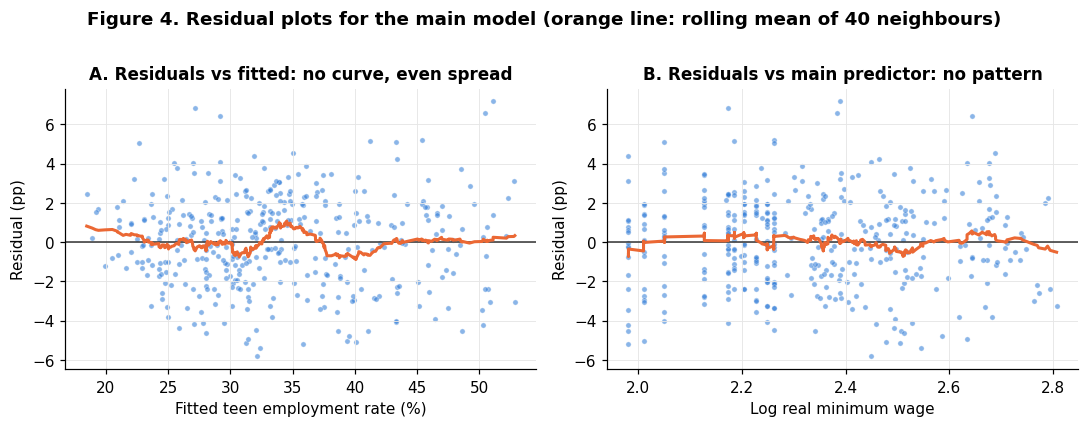

Std. dev. of residuals by fitted-value third:
 low       2.13
middle    2.23
high      2.60


/tmp/ipykernel_460/3791191038.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  spread = pd.Series(resid.values).groupby(pd.qcut(fitted.values, 3, labels=["low", "middle", "high"])).std()


In [16]:
ols_main = smf.ols(SPECS["(5) FE, all controls (main)"], data=sample).fit()     # same coefficients, classical SEs
resid, fitted = ols_main.resid, ols_main.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, x, xlabel in [(axes[0], fitted, "Fitted teen employment rate (%)"),
                      (axes[1], sample["log_real_mw"], "Log real minimum wage")]:
    ax.scatter(x, resid, s=12, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.4)
    ax.axhline(0, color="#333333", linewidth=1)
    order = np.argsort(x.values)
    smooth = pd.Series(resid.values[order]).rolling(40, center=True, min_periods=10).mean()
    ax.plot(x.values[order], smooth, color=ORANGE, linewidth=2)
    ax.set_xlabel(xlabel); ax.set_ylabel("Residual (pp)")
axes[0].set_title("A. Residuals vs fitted: no curve, even spread")
axes[1].set_title("B. Residuals vs main predictor: no pattern")
fig.suptitle("Figure 4. Residual plots for the main model (orange line: rolling mean of 40 neighbours)", fontweight="bold", y=1.01)
plt.tight_layout(); plt.savefig("fig4_residuals.png", dpi=200, bbox_inches="tight"); plt.show()

# Spread of residuals by fitted-value tercile, to put a number on the funnel.
spread = pd.Series(resid.values).groupby(pd.qcut(fitted.values, 3, labels=["low", "middle", "high"])).std()
print("Std. dev. of residuals by fitted-value third:\n", spread.round(2).to_string())

In [17]:
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(resid, ols_main.model.exog)
print(f"Breusch–Pagan test (all regressors incl. dummies): LM = {bp_lm:.1f}, p = {bp_p:.4f}")
bp2 = het_breuschpagan(resid, sm.add_constant(sample[["log_real_mw", "adult_unemp", "teen_share", "log_real_inc"]]))
print(f"Breusch–Pagan test (the 4 continuous regressors only): LM = {bp2[0]:.1f}, p = {bp2[1]:.4f}")
se_compare = pd.DataFrame({"classical SE": ols_main.bse, "robust (HC1) SE": main.bse}).loc[list(ROWS)].round(3)
se_compare

Breusch–Pagan test (all regressors incl. dummies): LM = 78.2, p = 0.0576
Breusch–Pagan test (the 4 continuous regressors only): LM = 3.0, p = 0.5496


,classical SE,robust (HC1) SE
log_real_mw,1.568,1.495
adult_unemp,0.222,0.235
teen_share,0.411,0.435
log_real_inc,3.474,3.865


**Constant variance.** Panel A of Figure 4 shows no curvature (the rolling mean stays near zero), so the linear form looks adequate, and the spread is fairly even: the residual standard deviation rises only from about 2.1 to 2.6 points between the lowest and highest third of fitted values. The Breusch–Pagan test does **not** reject constant variance at the 5% level: p ≈ 0.06 using all regressors including the dummies, and p ≈ 0.55 using the four continuous regressors. Because the first test is borderline and the outcome is a survey estimate whose precision differs by state size, I report **HC1 robust standard errors anyway**. They differ from the classical ones only in the second decimal, so the conclusion does not depend on the choice. Panel B shows no pattern against the minimum wage, so there is no sign that the relationship is non-linear in the log wage.

In [18]:
X_cont = ["log_real_mw", "adult_unemp", "teen_share", "log_real_inc"]
# (a) VIF in the pooled model: how much the four regressors overlap with each other.
Xp = sm.add_constant(sample[X_cont])
vif_pooled = pd.Series([variance_inflation_factor(Xp.values, i) for i in range(1, Xp.shape[1])], index=X_cont)
# (b) VIF in the main model: how much each regressor is explained by the others PLUS the state and year dummies.
#     VIF = 1 / (1 - R^2) from regressing the variable on everything else in the main model.
vif_fe = {}
for v in X_cont:
    others = " + ".join([o for o in X_cont if o != v] + ["C(state)", "C(year)"])
    r2 = smf.ols(f"{v} ~ {others}", data=sample).fit().rsquared
    vif_fe[v] = 1 / (1 - r2)
vif = pd.DataFrame({"VIF, pooled model": vif_pooled, "VIF, main model (with dummies)": pd.Series(vif_fe)}).round(1)
vif.index = vif.index.map(ROWS)
vif

,"VIF, pooled model","VIF, main model (with dummies)"
Log real minimum wage,1.5,6.4
"Unemployment rate, 20+ (%)",1.1,6.8
Teen share of 16+ pop. (%),1.1,3.5
Log real median HH income,1.3,19.6


**Variance inflation.** Among themselves the four regressors barely overlap (pooled VIFs of 1.1–1.5), so the controls are not collinear with each other. Once state and year dummies are in, the VIFs rise: about 6 for the minimum wage and about 20 for income. That is the expected cost of fixed effects, not an error. Most of the variation in a state's minimum wage is either its permanent level (absorbed by the state dummy) or the nationwide trend (absorbed by the year dummies), and only the remaining state-specific changes identify β₁. A VIF of 6.4 means the minimum-wage standard error is about √6.4 ≈ 2.5 times what it would be if that variation were unrelated to the other regressors. That is a large part of why the estimate is imprecise with 386 observations. Income's VIF of about 20 means real median income barely moves within a state apart from the national trend, so its own coefficient is very imprecise (SE ≈ 3.9). That does not harm the minimum-wage estimate, which changes by only 0.04 when income is dropped (column 4). The fix is more within-state variation (more years, monthly data), not dropping a control.

Cook's distance threshold 4/n = 0.0104; observations above it: 36
            state  year  teen_epop  real_mw  adult_unemp  cooks_d
395  Rhode Island  2020       26.5    13.94         8.88     0.06
116        Hawaii  2021       22.9    11.69         6.02     0.04
5         Alabama  2020       34.0     8.79         5.85     0.04
455       Vermont  2020       34.7    13.28         5.61     0.03
150          Iowa  2015       50.6     9.60         3.23     0.03
60    Connecticut  2015       21.5    12.11         5.17     0.03
271      Nebraska  2016       47.6    11.76         3.04     0.02
238     Minnesota  2023       58.3    10.90         2.78     0.02

Main MW coefficient, all 386 obs: -2.60 (SE 1.49)
Dropping the 36 high-influence obs:   -1.98 (SE 1.30), N = 350


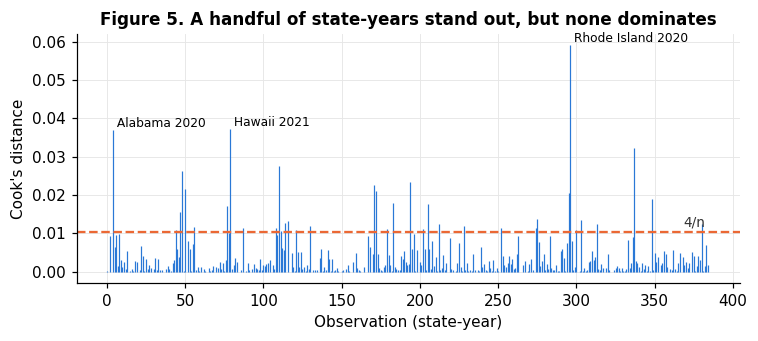

In [19]:
infl = ols_main.get_influence()
cooks = pd.Series(infl.cooks_distance[0], index=sample.index)
threshold = 4 / len(sample)
flagged = cooks[cooks > threshold].sort_values(ascending=False)
print(f"Cook's distance threshold 4/n = {threshold:.4f}; observations above it: {len(flagged)}")
top = sample.loc[flagged.index[:8], ["state", "year", "teen_epop", "real_mw", "adult_unemp"]].assign(cooks_d=flagged.iloc[:8].round(3))
display(top.round(2)) if "display" in globals() else print(top.round(2))

robust_check = smf.ols(SPECS["(5) FE, all controls (main)"], data=sample.drop(flagged.index)).fit(cov_type="HC1")
print(f"\nMain MW coefficient, all {int(main.nobs)} obs: {main.params['log_real_mw']:.2f} (SE {main.bse['log_real_mw']:.2f})")
print(f"Dropping the {len(flagged)} high-influence obs:   {robust_check.params['log_real_mw']:.2f} "
      f"(SE {robust_check.bse['log_real_mw']:.2f}), N = {int(robust_check.nobs)}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.vlines(range(len(cooks)), 0, cooks.values, color=BLUE, linewidth=0.8)
ax.axhline(threshold, color=ORANGE, linewidth=1.5, linestyle="--")
ax.text(len(cooks) * 0.99, threshold * 1.15, "4/n", color="#333333", ha="right", fontsize=9)
for idx in flagged.index[:3]:
    pos = sample.index.get_loc(idx)
    ax.text(pos, cooks[idx], f" {sample.loc[idx, 'state']} {sample.loc[idx, 'year']}", fontsize=8, va="bottom")
ax.set_xlabel("Observation (state-year)"); ax.set_ylabel("Cook's distance")
ax.set_title("Figure 5. A handful of state-years stand out, but none dominates")
plt.tight_layout(); plt.savefig("fig5_cooks_distance.png", dpi=200); plt.show()

**Influential observations.** 36 state-years lie above the usual 4/n cut-off, but the largest Cook's distance is about 0.06, far below the level (around 1) at which one observation would move the fit substantially. The most influential points are mostly small states (Rhode Island, Hawaii, Vermont), where the teen estimate rests on the fewest survey respondents, and several are from the 2020 pandemic year. Re-estimating without all 36 moves the minimum-wage coefficient from −2.60 to −1.98: same sign, somewhat smaller. No single state-year drives the result, and if anything the influential points make the estimate more negative.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

**What would have to be true for β₁ to be causal?** Net of permanent state differences and national year effects, the timing of each state's increases would have to be unrelated to anything else changing its teen employment. Three reasons to doubt it:

1. **Policy timing.** Legislatures raise wages when labour markets are strong and phase increases in over years; if increases coincide with rising teen employment, β₁ is pulled toward zero. Adult unemployment absorbs part of this, not expectations or booms in teen-heavy sectors.
2. **Different trends.** Raising states are mostly coastal and metropolitan, and their teen employment could trend differently for unrelated reasons (school enrolment, immigration). State dummies remove differences in levels, not trends. A **difference-in-differences** design comparing the change in raising states with the change in similar non-raising states (ideally bordering counties) would buy a like-for-like comparison, at the cost of assuming parallel paths without the increase. Figure 3 is consistent with that but cannot prove it. I do not estimate it, because its standard errors need methods the course has not covered.
3. **Measurement and selection.** The outcome is a noisy small-sample estimate, which widens standard errors; MNAR suppression likely makes β₁ too negative (Section 1); and within-state errors are correlated, so robust SEs overstate precision (Appendix A2).

**So β₁ is not causal.** It is a **conditional association**: the within-state, net-of-national-trend relationship between a state's real minimum wage and its teen employment rate, holding adult unemployment, teen share and income fixed, in 48 states, 2015–2024.

**Conclusion.** Higher-minimum-wage states have clearly lower teen employment, but almost all of that is a difference between states. Compared with itself over 2015–2024, a state with a 10% higher real minimum wage has teen employment about a quarter of a point lower: too imprecise to distinguish from zero, but precise enough to rule out the large losses the raw comparison suggests. A reader can be fairly confident this decade's increases did not bring large teen job losses, but should not read the result as no effect or as causal. With another month I would use monthly CPS microdata (exact effective dates, small states), compare bordering counties, and estimate the difference-in-differences design with proper standard errors.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [20]:
# A1. Full statsmodels output for the main model (for reference only; Table 2 is the formatted version).
print(main.summary().tables[1].as_text()[:1200] + "\n... (state and year dummies omitted)")

                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept                     42.6535     42.444      1.005      0.315     -40.535     125.842
C(state)[T.Alaska]             4.8074      2.203      2.182      0.029       0.489       9.126
C(state)[T.Arizona]            3.9378      1.866      2.111      0.035       0.281       7.595
C(state)[T.Arkansas]           2.8772      1.671      1.721      0.085      -0.399       6.153
C(state)[T.California]        -3.7506      2.095     -1.790      0.073      -7.856       0.355
C(state)[T.Colorado]           8.6817      2.696      3.221      0.001       3.398      13.965
C(state)[T.Connecticut]        0.8148      2.781      0.293      0.770      -4.636       6.266
C(state)[T.Delaware]           7.8989      2.248      3.513      0.000       3.492      12.306
C(state)[T.Florida]           -2.5008      1.633  

In [21]:
# A2. Sensitivity: standard errors clustered by state (allow errors to be correlated within a state over time).
#     Not covered in the course; shown only to show how much the robust SE may understate uncertainty.
clustered = smf.ols(SPECS["(5) FE, all controls (main)"], data=sample).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(sample["state"])[0]})
print(f"Log real MW: b = {clustered.params['log_real_mw']:.2f}; HC1 SE = {main.bse['log_real_mw']:.2f}; "
      f"state-clustered SE = {clustered.bse['log_real_mw']:.2f} (p = {clustered.pvalues['log_real_mw']:.3f})")

Log real MW: b = -2.60; HC1 SE = 1.49; state-clustered SE = 1.98 (p = 0.190)


In [22]:
# A3. Sensitivity: weight each state-year by its teen population (big states count more, noisy small states less).
weighted = smf.wls(SPECS["(5) FE, all controls (main)"], data=sample, weights=sample["pop_teen"]).fit(cov_type="HC1")
print(f"Teen-population-weighted main model, log real MW: b = {weighted.params['log_real_mw']:.2f} "
      f"(SE {weighted.bse['log_real_mw']:.2f})")

Teen-population-weighted main model, log real MW: b = -1.71 (SE 1.43)


In [23]:
# A4. Save tables for the report.
os.makedirs("output", exist_ok=True)
summary_fmt.to_csv("output/table1_summary.csv")
reg_table.to_csv("output/table2_regressions.csv")
vif.to_csv("output/table3_vif.csv")
df.to_csv("output/panel_state_year.csv", index=False)
print("Saved:", sorted(os.listdir("output")))

Saved: ['panel_state_year.csv', 'table1_summary.csv', 'table2_regressions.csv', 'table3_vif.csv']


## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [24]:
REPORT_NUMBERS = {
    "Section 1: state-years in the merged panel": len(df),
    "Section 1: state-years with teen data missing": int(df["teen_missing"].sum()),
    "Section 1: % of state-years missing": round(100 * df["teen_missing"].mean(), 1),
    "Section 1: rows in the final sample": len(sample),
    "Section 1: states in the final sample": sample["state"].nunique(),
    "Section 1: states whose binding wage changed": int((sample.groupby("state")["mw"].nunique() > 1).sum()),
    "Section 1: states at federal $7.25 all decade": int(n_states["Stayed at federal $7.25"]),
    "Section 1: mean teen employment rate (%)": round(sample["teen_epop"].mean(), 1),
    "Section 1: missingness logit, coef on overall employment rate": round(miss_logit.params["epop_all"], 3),
    "Section 1: missingness logit, p on overall employment rate": f"{miss_logit.pvalues['epop_all']:.4f}",
    "Section 1: median 16+ population, published vs missing (thousands)": (float(compare.iloc[0, 1]), float(compare.iloc[1, 1])),
    "Section 2: skew of teen employment rate": round(sample["teen_epop"].skew(), 2),
    "Section 2: pooled slope, pp per log point": round(pooled_slope, 2),
    "Section 2: within slope, pp per log point": round(within_slope, 2),
    "Section 2: gap federal-floor minus raised, 2015 (pp)": round(gap.loc[2015], 1),
    "Section 2: gap federal-floor minus raised, 2024 (pp)": round(gap.loc[2024], 1),
    "Section 3: coefficient on log real MW, main model": round(b, 2),
    "Section 3: robust SE, log real MW": round(se, 2),
    "Section 3: p-value, log real MW": round(main.pvalues["log_real_mw"], 3),
    "Section 3: effect of 10% higher MW (pp)": round(b * np.log(1.1), 2),
    "Section 3: 10% higher MW as % of mean teen employment rate": round(100 * b * np.log(1.1) / mean_y, 1),
    "Section 4: SE inflation factor for MW, sqrt(VIF)": round(np.sqrt(vif_fe["log_real_mw"]), 1),
    "Section 3: 95% CI low, 10% higher MW (pp)": round(ci[0] * np.log(1.1), 2),
    "Section 3: 95% CI high, 10% higher MW (pp)": round(ci[1] * np.log(1.1), 2),
    "Section 3: effect of 10% higher MW, pooled model (pp)": round(fits["(1) Pooled, no controls"].params["log_real_mw"] * np.log(1.1), 2),
    "Section 3: coefficient on adult unemployment": round(b_u, 2),
    "Section 3: 95% CI low, adult unemployment": round(float(ci_u[0]), 2),
    "Section 3: 95% CI high, adult unemployment": round(float(ci_u[1]), 2),
    "Section 3: MW coefficient, col (3) no adult unemp or income": round(fits["(3) FE, teen share only"].params["log_real_mw"], 2),
    "Section 3: MW coefficient, col (4) no income": round(fits["(4) FE, + adult unemp."].params["log_real_mw"], 2),
    "Section 3: R-squared, main model": round(main.rsquared, 3),
    "Section 3: median within-state change in log real MW": round(mw_range[mw_range > 0.01].median(), 2),
    "Section 4: Breusch-Pagan p-value, all regressors": round(bp_p, 4),
    "Section 4: Breusch-Pagan p-value, continuous regressors": round(bp2[1], 4),
    "Section 4: VIF log real income, main model": round(vif_fe["log_real_inc"], 1),
    "Section 4: largest Cook's distance": round(cooks.max(), 3),
    "Section 4: VIF log real MW, main model": round(vif_fe["log_real_mw"], 1),
    "Section 4: observations above Cook's 4/n": len(flagged),
    "Section 4: MW coefficient without influential obs": round(robust_check.params["log_real_mw"], 2),
    "Appendix: state-clustered SE, log real MW": round(clustered.bse["log_real_mw"], 2),
    "Appendix: weighted MW coefficient": round(weighted.params["log_real_mw"], 2),
    # --- further numbers quoted in the report ---
    "Section 1: states never published": sorted(set(STATES) - set(sample["state"])),
    "Section 1: jurisdictions that raised their binding wage (incl. DC)": int(n_states["Raised above $7.25"]),
    "Section 1: state-years with no state minimum-wage law": int(mw["no_state_law"].sum()),
    "Section 1: missingness logit, coef on log real MW": round(miss_logit.params["log_real_mw"], 3),
    "Section 1: missingness logit, p on log real MW": round(miss_logit.pvalues["log_real_mw"], 3),
    "Section 1: overall employment rate, published vs missing (%)": tuple(float(v) for v in compare["overall_employment_rate"].round(1)),
    "Section 1: real minimum wage, published vs missing (2024 $)": tuple(float(v) for v in compare["real_min_wage"].round(2)),
    "Section 1: median teen employment rate (%)": round(sample["teen_epop"].median(), 1),
    "Section 2: skew of real minimum wage": round(sample["real_mw"].skew(), 2),
    "Section 3: 95% CI on log real MW coefficient": (round(float(ci[0]), 2), round(float(ci[1]), 2)),
    "Section 3: robust SE, adult unemployment": round(se_u, 2),
    "Section 3: p-value, adult unemployment": round(main.pvalues["adult_unemp"], 3),
    "Section 3: SD of adult unemployment (pts)": round(sample["adult_unemp"].std(), 2),
    "Section 3: effect of a 1-SD rise in adult unemployment (pp)": round(b_u * sample["adult_unemp"].std(), 2),
    "Section 3: MW coefficient, col (2) pooled with controls": round(fits["(2) Pooled, controls"].params["log_real_mw"], 2),
    "Section 4: residual SD by fitted-value third (low, middle, high)": tuple(float(v) for v in spread.round(2)),
    "Section 4: Breusch-Pagan LM, all regressors": round(bp_lm, 1),
    "Section 4: Breusch-Pagan LM, continuous regressors": round(bp2[0], 1),
    "Section 4: classical SE, log real MW": round(ols_main.bse["log_real_mw"], 2),
    "Section 4: robust SE, log real income": round(main.bse["log_real_inc"], 2),
    "Section 4: VIF range without dummies": (round(float(vif_pooled.min()), 1), round(float(vif_pooled.max()), 1)),
    "Section 4: VIF adult unemployment, main model": round(vif_fe["adult_unemp"], 1),
    "Section 4: Cook's distance threshold 4/n": round(threshold, 4),
    "Section 4: SE and N without influential obs": (round(float(robust_check.bse["log_real_mw"]), 2), int(robust_check.nobs)),
    "Appendix: p-value with state-clustered SE": round(clustered.pvalues["log_real_mw"], 3),
    "Appendix: SE of weighted MW coefficient": round(weighted.bse["log_real_mw"], 2),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: state-years in the merged panel: 510
Section 1: state-years with teen data missing: 124
Section 1: % of state-years missing: 24.3
Section 1: rows in the final sample: 386
Section 1: states in the final sample: 48
Section 1: states whose binding wage changed: 28
Section 1: states at federal $7.25 all decade: 20
Section 1: mean teen employment rate (%): 33.7
Section 1: missingness logit, coef on overall employment rate: 0.127
Section 1: missingness logit, p on overall employment rate: 0.0001
Section 1: median 16+ population, published vs missing (thousands): (4527.0, 1136.5)
Section 2: skew of teen employment rate: 0.53
Section 2: pooled slope, pp per log point: -11.56
Section 2: within slope, pp per log point: -3.44
Section 2: gap federal-floor minus raised, 2015 (pp): 2.7
Section 2: gap federal-floor minus raised, 2024 (pp): 3.9
Section 3: coefficient on log real MW, main model: -2.6
Section 3: robust SE, log real MW: 1.49
Section 3: p-value, log real MW: 0.082
Section 3: ef

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.